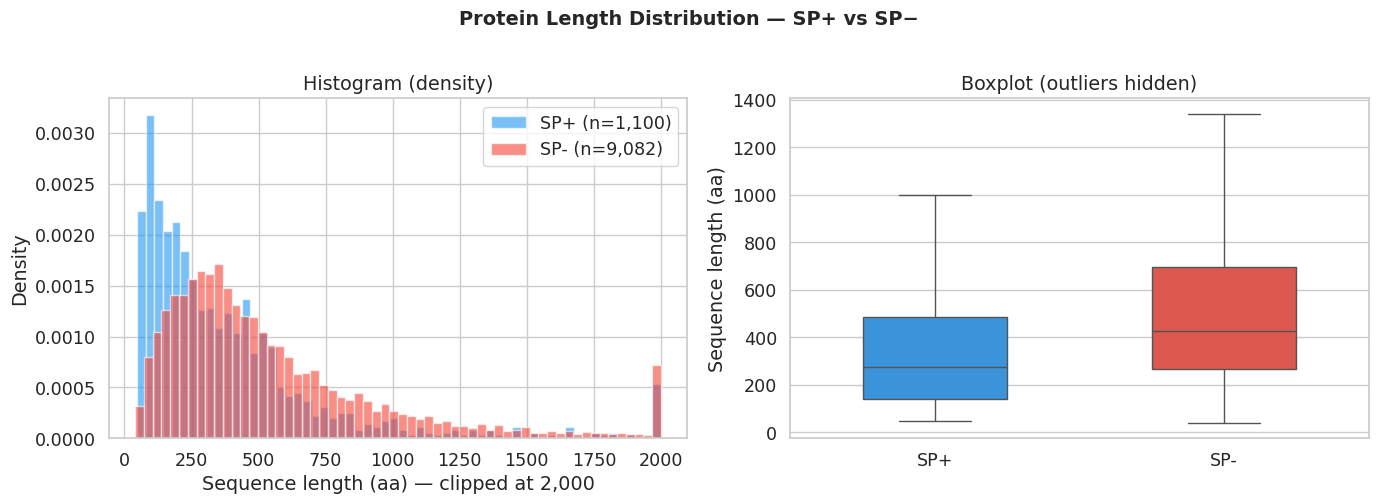

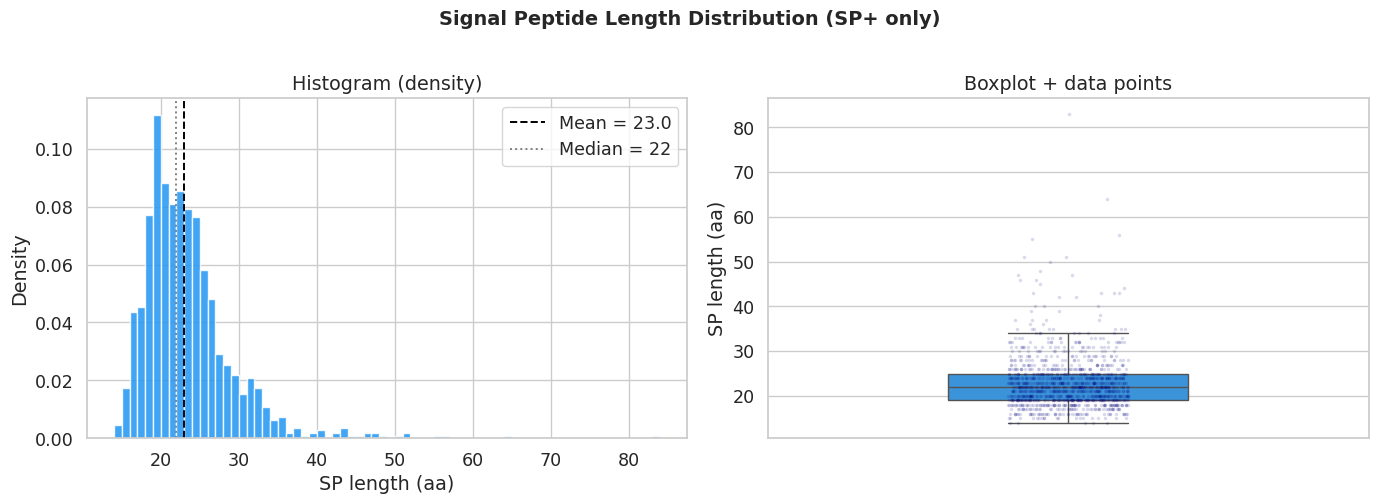

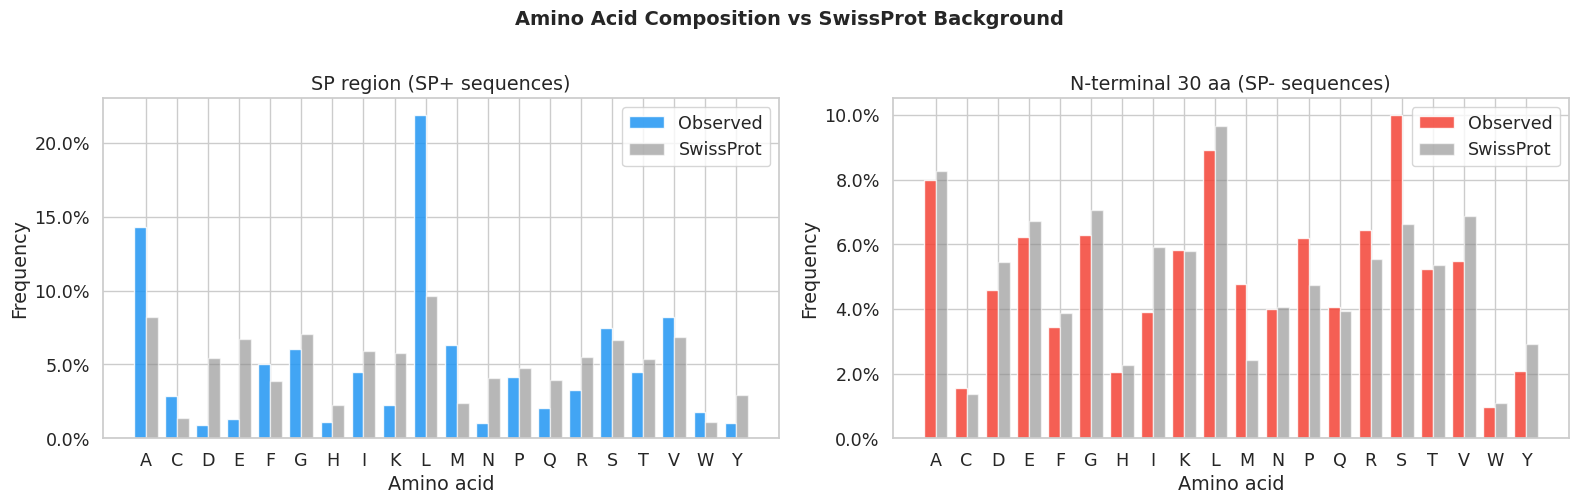

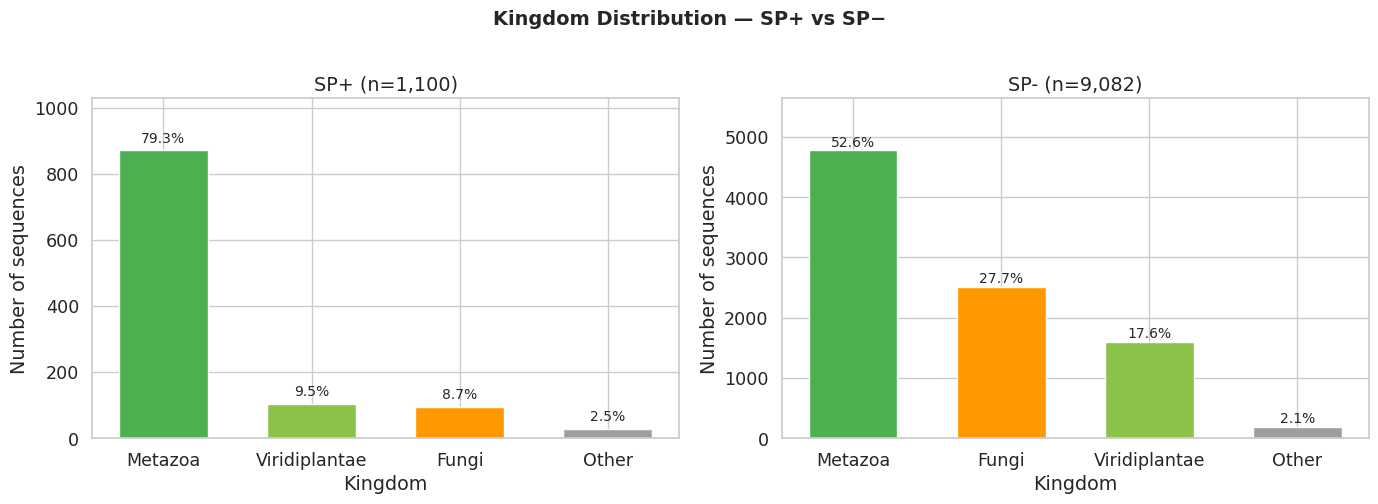

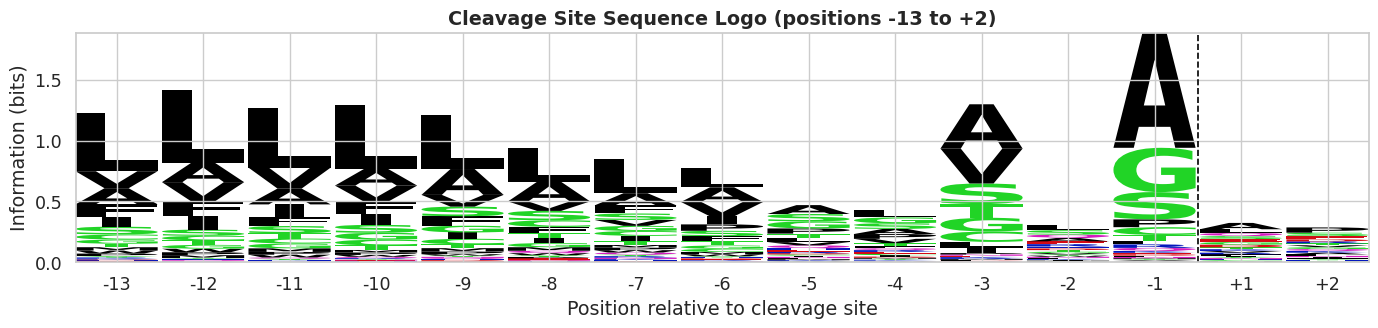

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import logomaker
from Bio import SeqIO

warnings.filterwarnings("ignore")
WORK_DIR = os.path.expanduser("~/LB2_Project")
os.chdir(WORK_DIR)
os.makedirs("figures", exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.15)
PALETTE = {"Positive (SP+)": "#2196F3", "Negative (SP-)": "#F44336"}

df_train = pd.read_csv("training_with_folds.tsv", sep="\t")
df_bench = pd.read_csv("benchmarking_set.tsv", sep="\t")
df_all = pd.concat([df_train, df_bench], ignore_index=True)

df_pos = df_all[df_all["label"] == 1].copy()
df_neg = df_all[df_all["label"] == 0].copy()

pos_seqs = {rec.id: str(rec.seq) for rec in SeqIO.parse("positive.fasta", "fasta")}
neg_seqs = {rec.id: str(rec.seq) for rec in SeqIO.parse("negative.fasta", "fasta")}

# --- Analysis 1: Protein Length Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Protein Length Distribution — SP+ vs SP−", fontsize=14, fontweight="bold", y=1.01)

lengths_pos = df_pos["Sequence length"]
lengths_neg = df_neg["Sequence length"]
clip = 2000

axes[0].hist(lengths_pos.clip(upper=clip), bins=60, alpha=0.6, color=PALETTE["Positive (SP+)"], label=f"SP+ (n={len(lengths_pos):,})", density=True)
axes[0].hist(lengths_neg.clip(upper=clip), bins=60, alpha=0.6, color=PALETTE["Negative (SP-)"], label=f"SP- (n={len(lengths_neg):,})", density=True)
axes[0].set_xlabel("Sequence length (aa) — clipped at 2,000")
axes[0].set_ylabel("Density")
axes[0].set_title("Histogram (density)")
axes[0].legend()

plot_df = pd.DataFrame({
    "Length": pd.concat([lengths_pos, lengths_neg], ignore_index=True),
    "Class": ["SP+"] * len(lengths_pos) + ["SP-"] * len(lengths_neg)
})
sns.boxplot(data=plot_df, x="Class", y="Length", ax=axes[1], palette={"SP+": PALETTE["Positive (SP+)"], "SP-": PALETTE["Negative (SP-)"]}, showfliers=False, width=0.5)
axes[1].set_xlabel("")
axes[1].set_ylabel("Sequence length (aa)")
axes[1].set_title("Boxplot (outliers hidden)")

plt.tight_layout()
plt.savefig("figures/01_protein_length.pdf", bbox_inches="tight")
plt.savefig("figures/01_protein_length.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Analysis 2: Signal Peptide Length Distribution ---
sp_lengths = df_pos["SP cleavage"].dropna().astype(int)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Signal Peptide Length Distribution (SP+ only)", fontsize=14, fontweight="bold", y=1.01)

axes[0].hist(sp_lengths, bins=range(sp_lengths.min(), sp_lengths.max() + 2), color=PALETTE["Positive (SP+)"], edgecolor="white", alpha=0.85, density=True)
axes[0].axvline(sp_lengths.mean(), color="black", linestyle="--", linewidth=1.4, label=f"Mean = {sp_lengths.mean():.1f}")
axes[0].axvline(sp_lengths.median(), color="gray", linestyle=":", linewidth=1.4, label=f"Median = {sp_lengths.median():.0f}")
axes[0].set_xlabel("SP length (aa)")
axes[0].set_ylabel("Density")
axes[0].set_title("Histogram (density)")
axes[0].legend()

sns.boxplot(y=sp_lengths, ax=axes[1], color=PALETTE["Positive (SP+)"], width=0.4, showfliers=False)
sns.stripplot(y=sp_lengths, ax=axes[1], color="navy", alpha=0.15, size=2.5, jitter=True)
axes[1].set_ylabel("SP length (aa)")
axes[1].set_title("Boxplot + data points")
axes[1].set_xticks([])

plt.tight_layout()
plt.savefig("figures/02_sp_length.pdf", bbox_inches="tight")
plt.savefig("figures/02_sp_length.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Analysis 3: Amino Acid Composition vs SwissProt Background ---
SWISSPROT_FREQ = {
    "A": 0.0825, "R": 0.0553, "N": 0.0406, "D": 0.0545, "C": 0.0138,
    "Q": 0.0393, "E": 0.0672, "G": 0.0707, "H": 0.0228, "I": 0.0591,
    "L": 0.0965, "K": 0.0580, "M": 0.0241, "F": 0.0386, "P": 0.0475,
    "S": 0.0664, "T": 0.0535, "W": 0.0109, "Y": 0.0291, "V": 0.0686
}
AA_ORDER = list("ACDEFGHIKLMNPQRSTVWY")

def compute_aa_freq(sequences):
    counts = {aa: 0 for aa in AA_ORDER}
    total = 0
    for seq in sequences:
        for aa in seq.upper():
            if aa in counts:
                counts[aa] += 1
                total += 1
    return {aa: counts[aa] / total for aa in AA_ORDER} if total > 0 else counts

sp_regions = [pos_seqs[row["Accession"]][:int(row["SP cleavage"])] for _, row in df_pos.iterrows() if row["Accession"] in pos_seqs]
neg_nterm = [neg_seqs[row["Accession"]][:30] for _, row in df_neg.iterrows() if row["Accession"] in neg_seqs]

freq_sp = compute_aa_freq(sp_regions)
freq_neg = compute_aa_freq(neg_nterm)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=False)
fig.suptitle("Amino Acid Composition vs SwissProt Background", fontsize=14, fontweight="bold", y=1.01)
x = np.arange(len(AA_ORDER))
width = 0.38

for ax, (freq, title, color) in zip(axes, [
    (freq_sp, "SP region (SP+ sequences)", PALETTE["Positive (SP+)"]),
    (freq_neg, "N-terminal 30 aa (SP- sequences)", PALETTE["Negative (SP-)"])
]):
    obs = [freq[aa] for aa in AA_ORDER]
    back = [SWISSPROT_FREQ[aa] for aa in AA_ORDER]
    ax.bar(x - width/2, obs, width, label="Observed", color=color, alpha=0.85)
    ax.bar(x + width/2, back, width, label="SwissProt", color="#888", alpha=0.60)
    ax.set_xticks(x)
    ax.set_xticklabels(AA_ORDER)
    ax.set_xlabel("Amino acid")
    ax.set_ylabel("Frequency")
    ax.set_title(title)
    ax.legend()
    ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1, decimals=1))

plt.tight_layout()
plt.savefig("figures/03_aa_composition.pdf", bbox_inches="tight")
plt.savefig("figures/03_aa_composition.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Analysis 4: Taxonomic (Kingdom) Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Kingdom Distribution — SP+ vs SP−", fontsize=14, fontweight="bold", y=1.01)
kingdom_colors = {"Metazoa": "#4CAF50", "Viridiplantae": "#8BC34A", "Fungi": "#FF9800", "Other": "#9E9E9E"}

for ax, (df_sub, title) in zip(axes, [(df_pos, f"SP+ (n={len(df_pos):,})"), (df_neg, f"SP- (n={len(df_neg):,})")]):
    counts = df_sub["Kingdom"].value_counts()
    pcts = counts / counts.sum() * 100
    colors = [kingdom_colors.get(k, "#BDBDBD") for k in counts.index]
    bars = ax.bar(counts.index, counts.values, color=colors, edgecolor="white", width=0.6)
    for bar, pct in zip(bars, pcts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15, f"{pct:.1f}%", ha="center", va="bottom", fontsize=10)
    ax.set_title(title)
    ax.set_xlabel("Kingdom")
    ax.set_ylabel("Number of sequences")
    ax.set_ylim(0, counts.max() * 1.18)

plt.tight_layout()
plt.savefig("figures/04_kingdom_distribution.pdf", bbox_inches="tight")
plt.savefig("figures/04_kingdom_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Analysis 5: Cleavage Site Sequence Logo (-13 to +2) ---
WINDOW_BEFORE, WINDOW_AFTER = 13, 2
WINDOW_SIZE = WINDOW_BEFORE + WINDOW_AFTER
cleavage_windows = []

for _, row in df_pos.iterrows():
    acc = row["Accession"]
    cleavage = int(row["SP cleavage"])
    if acc in pos_seqs:
        seq = pos_seqs[acc]
        start, end = cleavage - WINDOW_BEFORE, cleavage + WINDOW_AFTER
        if 0 <= start and end <= len(seq):
            w = seq[start:end].upper()
            if len(w) == WINDOW_SIZE and all(aa in AA_ORDER for aa in w):
                cleavage_windows.append(w)

counts_df = logomaker.alignment_to_matrix(cleavage_windows, to_type="information")
fig, ax = plt.subplots(figsize=(14, 3.5))
logomaker.Logo(counts_df, ax=ax, color_scheme="weblogo_protein")
pos_labels = [str(i) for i in range(-WINDOW_BEFORE, 0)] + ["+1", "+2"]
ax.set_xticks(range(WINDOW_SIZE))
ax.set_xticklabels(pos_labels)
ax.axvline(WINDOW_BEFORE - 0.5, color="black", linestyle="--", linewidth=1.2)
ax.set_xlabel("Position relative to cleavage site")
ax.set_ylabel("Information (bits)")
ax.set_title("Cleavage Site Sequence Logo (positions -13 to +2)", fontweight="bold")

plt.tight_layout()
plt.savefig("figures/05_cleavage_logo.pdf", bbox_inches="tight")
plt.savefig("figures/05_cleavage_logo.png", dpi=150, bbox_inches="tight")
plt.show()